In [ ]:
#Marketing Campaigns

#Problem scenario: 
#Marketing mix stands as a widely utilized concept in the execution of marketing strategies. 
# It encompasses various facets within a comprehensive marketing plan, with a central focus on the four Ps of marketing: 
# product, price, place, and promotion.

#Problem objective:
# As a data scientist, you must conduct exploratory data analysis and hypothesis testing to enhance your comprehension of 
# the diverse factors influencing customer acquisition.

#Data description:
# The variables such as birth year, education, income, and others pertain to the first 'P' or 'People' in the tabular data presented to the user. 
# The expenditures on items like wine, fruits, and gold, are associated with ‘Product’. 
# Information relevant to sales channels, such as websites and stores, is connected to ‘Place’. 
# The fields discussing promotions and the outcomes of various campaigns are linked to ‘Promotion’.


In [ ]:
#1.	After importing the data, examine variables such as Dt_Customer and Income to verify their accurate importation.
#The dataframe 'data' is already loaded in the notebook.
import pandas as pd
import pandas as pd

# Load dataset
data = pd.read_csv("datasets/marketing_data.csv")

# Remove extra spaces from column names
data.columns = data.columns.str.strip()

# Check initial data types
print("Before Cleaning")
print(data[["Dt_Customer", "Income"]].head())
print(data[["Dt_Customer", "Income"]].dtypes)


# Convert Income to numeric
data["Income"] = (
    data["Income"]
    .astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

data["Income"] = pd.to_numeric(
    data["Income"],
    errors="coerce"
)

# Convert Dt_Customer to datetime
data["Dt_Customer"] = pd.to_datetime(
    data["Dt_Customer"],
    format="%m/%d/%y",
    errors="coerce"
)

# Verify results

print("\nAfter Cleaning")
print(data[["Dt_Customer", "Income"]].head())

print("\nData Types")
print(data[["Dt_Customer", "Income"]].dtypes)

print("\nMissing Values")
print("Income:", data["Income"].isnull().sum())
print("Dt_Customer:", data["Dt_Customer"].isnull().sum())

print("\nDataset Information")
data.info()


Before Cleaning
  Dt_Customer       Income
0     6/16/14  $84,835.00 
1     6/15/14  $57,091.00 
2     5/13/14  $67,267.00 
3     5/11/14  $32,474.00 
4      4/8/14  $21,474.00 
Dt_Customer    object
Income         object
dtype: object

After Cleaning
  Dt_Customer   Income
0  2014-06-16  84835.0
1  2014-06-15  57091.0
2  2014-05-13  67267.0
3  2014-05-11  32474.0
4  2014-04-08  21474.0

Data Types
Dt_Customer    datetime64[ns]
Income                float64
dtype: object

Missing Values
Income: 24
Dt_Customer: 0

Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 28 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   ID                   2240 non-null   int64         
 1   Year_Birth           2240 non-null   int64         
 2   Education            2240 non-null   object        
 3   Marital_Status       2240 non-null   object        
 4   Income 

In [86]:
print(data["Education"].value_counts())
print(data["Marital_Status"].value_counts())
print(data["Income"].isnull().sum())

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64
Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
YOLO          2
Absurd        2
Name: count, dtype: int64
2240


In [97]:
#2.	There are missing income values for some customers. Conduct missing value imputation, considering that customers with similar education and marital status tend to have comparable yearly incomes, on average. It may be necessary to cleanse the data before proceeding. Specifically, scrutinize the categories of education and marital status for data cleaning. 
# Check missing values in Income
print("Missing Income Values Before Imputation:")
print(data["Income"].isnull().sum())

# ----------------------------------
# Examine Education Categories
# ----------------------------------

print("\nEducation Categories Before Cleaning:")
print(data["Education"].value_counts())

# Group education levels into broader categories
data["Education"] = data["Education"].replace({
    "Basic": "Undergraduate",
    "2n Cycle": "Undergraduate",
    "Graduation": "Graduate",
    "Master": "Postgraduate",
    "PhD": "Postgraduate"
})

print("\nEducation Categories After Cleaning:")
print(data["Education"].value_counts())

# ----------------------------------
# Examine Marital Status Categories
# ----------------------------------

print("\nMarital Status Before Cleaning:")
print(data["Marital_Status"].value_counts())

# Consolidate rare and similar categories
data["Marital_Status"] = data["Marital_Status"].replace({
    "Together": "Partner",
    "Married": "Partner",
    "YOLO": "Single",
    "Absurd": "Single",
    "Alone": "Single"
})

print("\nMarital Status After Cleaning:")
print(data["Marital_Status"].value_counts())

# ----------------------------------
# Income Imputation
# ----------------------------------

data["Income"] = data.groupby(
    ["Education", "Marital_Status"]
)["Income"].transform(
    lambda x: x.fillna(x.mean())
)

# ----------------------------------
# Verification
# ----------------------------------

print("\nMissing Income Values After Imputation:")
print(data["Income"].isnull().sum())

print("\nIncome Summary Statistics:")
print(data["Income"].describe())

Missing Income Values Before Imputation:
0

Education Categories Before Cleaning:
Education
Graduate         1127
Postgraduate      856
Undergraduate     257
Name: count, dtype: int64

Education Categories After Cleaning:
Education
Graduate         1127
Postgraduate      856
Undergraduate     257
Name: count, dtype: int64

Marital Status Before Cleaning:
Marital_Status
Partner     1444
Single       487
Divorced     232
Widow         77
Name: count, dtype: int64

Marital Status After Cleaning:
Marital_Status
Partner     1444
Single       487
Divorced     232
Widow         77
Name: count, dtype: int64

Missing Income Values After Imputation:
0

Income Summary Statistics:
count      2240.000000
mean      52245.219881
std       25042.260053
min        1730.000000
25%       35538.750000
50%       51445.500000
75%       68289.750000
max      666666.000000
Name: Income, dtype: float64


In [102]:
#3. Create variables to represent the total number of children, age, and total spending.
# a. Derive the total purchases from the number of transactions across the three channels.

# TotalChildren calculated as the sum of Kidhome and Teenhome.
data["TotalChildren"] = (
    data["Kidhome"] +
    data["Teenhome"]
)

# Age
# Using current year
data["Age"] = 2024 - data["Year_Birth"]

# TotalSpending calculated as the total expenditure across all product categories.
data["TotalSpending"] = (
    data["MntWines"] +
    data["MntFruits"] +
    data["MntMeatProducts"] +
    data["MntFishProducts"] +
    data["MntSweetProducts"] +
    data["MntGoldProds"]
)

# TotalPurchases calculated by summing purchases made through web, catalog, and store channels.
data["TotalPurchases"] = (
    data["NumWebPurchases"] +
    data["NumCatalogPurchases"] +
    data["NumStorePurchases"]
)

# Verify New Features
print(
    data[
        [
            "TotalChildren",
            "Age",
            "TotalSpending",
            "TotalPurchases"
        ]
    ].head()
)

print("\nSummary Statistics")
print(
    data[
        [
            "TotalChildren",
            "Age",
            "TotalSpending",
            "TotalPurchases"
        ]
    ].describe()
)

   TotalChildren  Age  TotalSpending  TotalPurchases
0              0   54           1190              14
1              0   63            577              17
2              1   66            251              10
3              2   57             11               3
4              1   35             91               6

Summary Statistics
       TotalChildren          Age  TotalSpending  TotalPurchases
count    2240.000000  2240.000000    2240.000000     2240.000000
mean        0.950446    55.194196     605.798214       12.537054
std         0.751803    11.984069     602.249288        7.205741
min         0.000000    28.000000       5.000000        0.000000
25%         0.000000    47.000000      68.750000        6.000000
50%         1.000000    54.000000     396.000000       12.000000
75%         1.000000    65.000000    1045.500000       18.000000
max         3.000000   131.000000    2525.000000       32.000000



Histograms STARTS


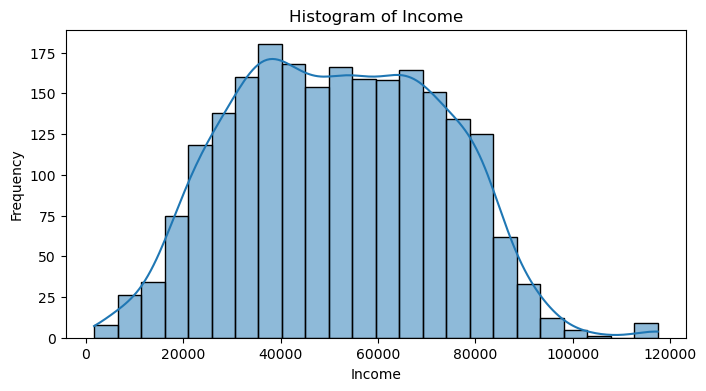

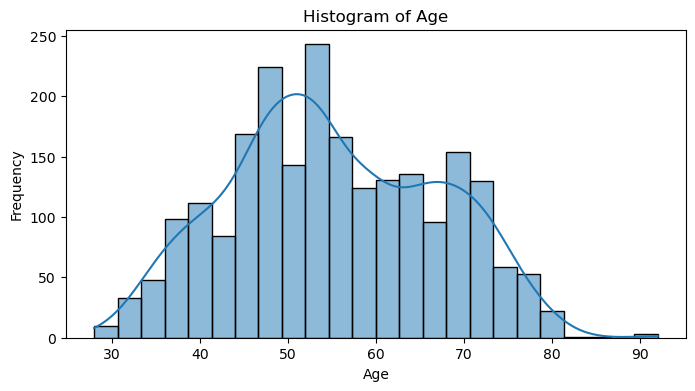

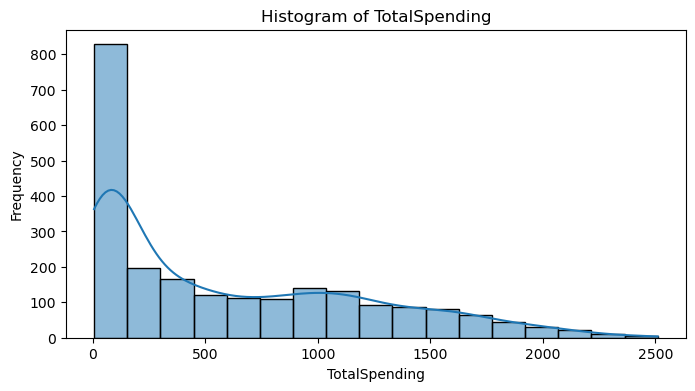

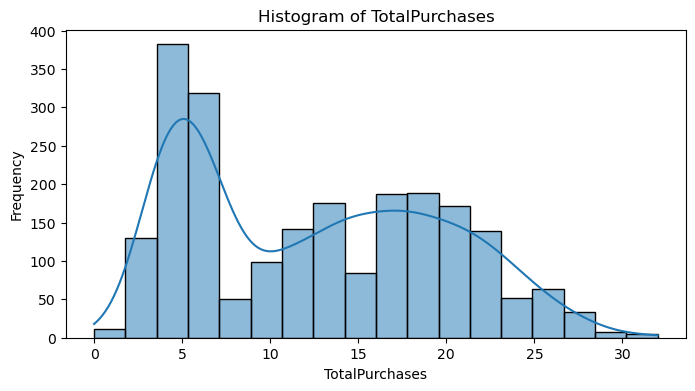


Histograms ENDS

Box Plots STARTS


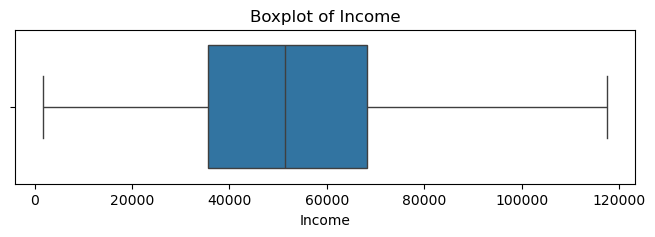

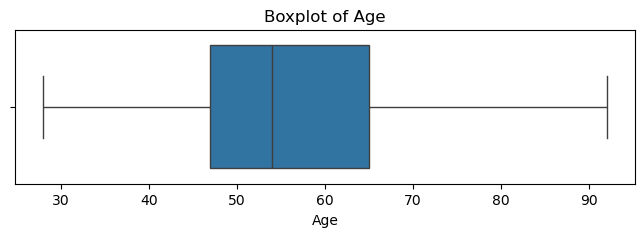

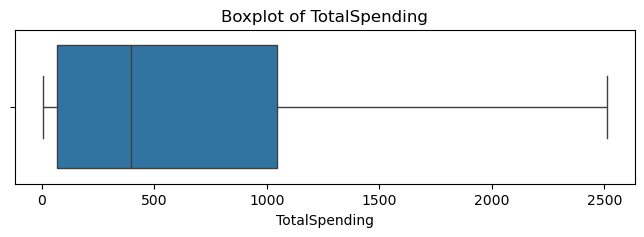

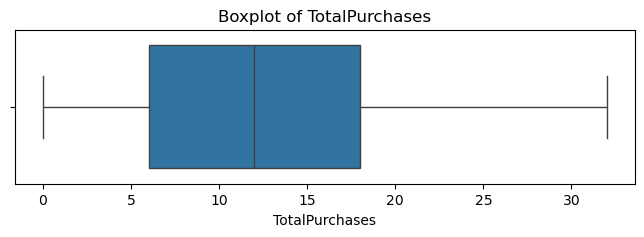


Box Plots ENDS

Detect Outliers using IQR STARTS

Column: Income
Lower Bound: -13587.75
Upper Bound: 117416.25
Number of Outliers: 0

Column: Age
Lower Bound: 20.0
Upper Bound: 92.0
Number of Outliers: 0

Column: TotalSpending
Lower Bound: -1396.38
Upper Bound: 2510.62
Number of Outliers: 0

Column: TotalPurchases
Lower Bound: -12.0
Upper Bound: 36.0
Number of Outliers: 0

Detect Outliers using IQR ENDS

Outlier Treatment using Capping STARTS
              Income          Age  TotalSpending  TotalPurchases
count    2240.000000  2240.000000    2240.000000     2240.000000
mean    51873.118988    55.147768     605.779408       12.537054
std     20941.380856    11.771725     602.189559        7.205741
min      1730.000000    28.000000       5.000000        0.000000
25%     35538.750000    47.000000      68.750000        6.000000
50%     51445.500000    54.000000     396.000000       12.000000
75%     68289.750000    65.000000    1045.500000       18.000000
max    117416.250000    92.00000

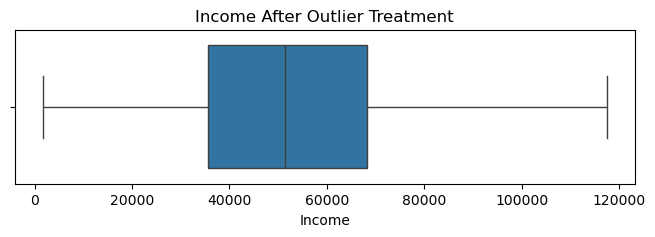

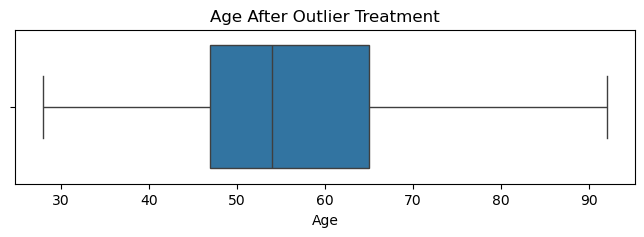

In [114]:
#4.	Generate box plots and histograms to gain insights into the distributions and identify outliers. 
#Implement outlier treatment as needed.
import matplotlib.pyplot as plt
import seaborn as sns

# Histograms
print("\nHistograms STARTS")
numerical_cols = [
    "Income",
    "Age",
    "TotalSpending",
    "TotalPurchases"
]

for col in numerical_cols:
    plt.figure(figsize=(8,4))
    sns.histplot(
        data[col],
        kde=True
    )
    plt.title(f"Histogram of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()
print("\nHistograms ENDS")

# Box Plots
print("\nBox Plots STARTS")
for col in numerical_cols:
    plt.figure(figsize=(8,2))
    sns.boxplot(x=data[col])
    plt.title(f"Boxplot of {col}")
    plt.show()
print("\nBox Plots ENDS")

# Outlier Treatment using IQR method
# Function to detect outliers
print("\nDetect Outliers using IQR STARTS")
def detect_outliers_iqr(df, column):

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print("\nColumn:", column)
    print("Lower Bound:", round(lower_bound,2))
    print("Upper Bound:", round(upper_bound,2))
    print("Number of Outliers:", len(outliers))

for col in numerical_cols:
    detect_outliers_iqr(data, col)
print("\nDetect Outliers using IQR ENDS")

# Function to cap outliers
print("\nOutlier Treatment using Capping STARTS")
def cap_outliers(df, column):

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df[column] = df[column].clip(
        lower=lower_bound,
        upper=upper_bound
    )

    return df

# Apply treatment only on variables with significant outliers

outlier_cols = [
    "Income",
    "Age"
]

for col in outlier_cols:
    data = cap_outliers(data, col)

print(
    data[
        [
            "Income",
            "Age",
            "TotalSpending",
            "TotalPurchases"
        ]
    ].describe()
)
print("\nOutlier Treatment using Capping ENDS")

for col in outlier_cols:

    plt.figure(figsize=(8,2))

    sns.boxplot(x=data[col])

    plt.title(f"{col} After Outlier Treatment")

    plt.show()

In [117]:
#5.	Apply ordinal and one-hot encoding based on the various types of categorical variables.

# Ordinal Encoding for Education
print("\nOrdinal Encoding for Education STARTS")
education_order = {
    "Undergraduate": 1,
    "Graduate": 2,
    "Postgraduate": 3
}

data["Education_Encoded"] = data["Education"].map(
    education_order
)

print("Education Encoding:")
print(
    data[
        ["Education", "Education_Encoded"]
    ].drop_duplicates()
)
print("\nOrdinal Encoding for Education ENDS")

# One-Hot Encoding for Marital Status
print("\nOne-Hot Encoding for Marital Status STARTS")
# Check if already encoded
if "Marital_Status" in data.columns:

    data = pd.get_dummies(
        data,
        columns=["Marital_Status"],
        drop_first=True,
        dtype=int
    )

    print("\nOne-Hot Encoding Applied Successfully")

else:

    print("\nMarital_Status already encoded")
print("\nOne-Hot Encoding for Marital Status ENDS")

print("\nEncoded Columns:")

print(
    [col for col in data.columns
     if "Marital_Status" in col]
)

print("\nData Sample")

print(data.head())


Ordinal Encoding for Education STARTS
Education Encoding:
       Education  Education_Encoded
0       Graduate                  2
5   Postgraduate                  3
6  Undergraduate                  1

Ordinal Encoding for Education ENDS

One-Hot Encoding for Marital Status STARTS

Marital_Status already encoded

One-Hot Encoding for Marital Status ENDS

Encoded Columns:
['Marital_Status_Partner', 'Marital_Status_Single', 'Marital_Status_Widow']

Data Sample
      ID  Year_Birth Education   Income  Kidhome  Teenhome Dt_Customer  \
0   1826        1970  Graduate  84835.0        0         0  2014-06-16   
1      1        1961  Graduate  57091.0        0         0  2014-06-15   
2  10476        1958  Graduate  67267.0        0         1  2014-05-13   
3   1386        1967  Graduate  32474.0        1         1  2014-05-11   
4   5371        1989  Graduate  21474.0        1         0  2014-04-08   

   Recency  MntWines  MntFruits  ...  Complain  Country  TotalChildren  Age  \
0        0 


Correlation Heatmap STARTS


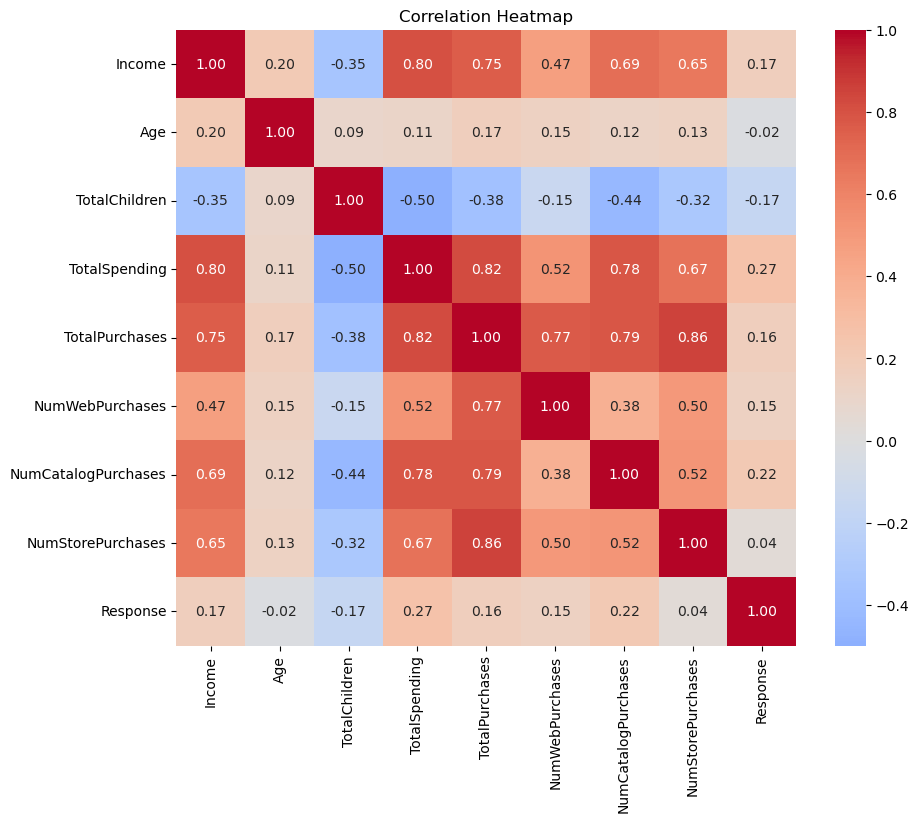


Correlation Heatmap ENDS


In [120]:
#6.	Generate a heatmap to illustrate the correlation between different pairs of variables.
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("\nCorrelation Heatmap STARTS")

important_cols = [
    "Income",
    "Age",
    "TotalChildren",
    "TotalSpending",
    "TotalPurchases",
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases",
    "Response"
]
# plot heatmap
plt.figure(figsize=(10,8))
sns.heatmap(
    data[important_cols].corr(),
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.show()
print("\nCorrelation Heatmap ENDS")

In [133]:
#7.	Test the following hypotheses:
#a.	Older individuals may not possess the same level of technological proficiency and may, therefore, lean toward traditional in-store shopping preferences.
#b.	Customers with children likely experience time constraints, making online shopping a more convenient option.
#c.	Sales at physical stores may face the risk of cannibalization by alternative distribution channels.
#d.	Does the United States significantly outperform the rest of the world in total purchase volumes?
from scipy.stats import ttest_ind, pearsonr
# Split customers by median age
median_age = data["Age"].median()
older_customers = data[
    data["Age"] >= median_age
]

younger_customers = data[
    data["Age"] < median_age
]

# independent t-test
t_stat, p_value = ttest_ind(
    older_customers["NumStorePurchases"],
    younger_customers["NumStorePurchases"],
    equal_var=False
)
print("Hypothesis 7a:")
print("T-statistic:", t_stat)
print("P-value:", p_value)

print("\nInterpretation:")
if p_value < 0.05:
    print("Reject H0")
    print("Age significantly influences store purchases.")
else:
    print("Fail to Reject H0")
    print("No significant evidence found.")

print("==============================================================================")
print("Hypothesis 7b:")
customers_with_children = data[
    data["TotalChildren"] > 0
]

customers_without_children = data[
    data["TotalChildren"] == 0
]

t_stat, p_value = ttest_ind(
    customers_with_children["NumWebPurchases"],
    customers_without_children["NumWebPurchases"],
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

print("\nInterpretation:")
if p_value < 0.05:
    print("Reject H0")
    print("Customers with children shop online significantly more.")
else:
    print("Fail to Reject H0")
    print("No significant evidence found.")

print("==============================================================================")
print("Hypothesis 7c:")
# Store vs Web

corr_web, p_web = pearsonr(
    data["NumStorePurchases"],
    data["NumWebPurchases"]
)

# Store vs Catalog

corr_catalog, p_catalog = pearsonr(
    data["NumStorePurchases"],
    data["NumCatalogPurchases"]
)

print("Store vs Web")
print("Correlation:", corr_web)
print("P-value:", p_web)

print("\nStore vs Catalog")
print("Correlation:", corr_catalog)
print("P-value:", p_catalog)
print("\nInterpretation:")
print("Negative correlation → evidence of cannibalization.\nPositive correlation → channels complement each other.")

print("==============================================================================")
print("Hypothesis 7d:")
us_customers = data[
    data["Country"] == "US"
]

rest_of_world = data[
    data["Country"] != "US"
]

t_stat, p_value = ttest_ind(
    us_customers["TotalPurchases"],
    rest_of_world["TotalPurchases"],
    equal_var=False
)

print("Hypothesis 7(d)")
print("T-statistic:", t_stat)
print("P-value:", p_value)

print("\nInterpretation:")
if p_value < 0.05:
    print("Reject H0")
    print("US customers significantly outperform the rest of the world.")
else:
    print("Fail to Reject H0")
    print("No significant difference detected.")

Hypothesis 7a:
T-statistic: 6.563009554601882
P-value: 6.535889828284444e-11

Interpretation:
Reject H0
Age significantly influences store purchases.
Hypothesis 7b:
T-statistic: -3.541893836382714
P-value: 0.0004108102700005601

Interpretation:
Reject H0
Customers with children shop online significantly more.
Hypothesis 7c:
Store vs Web
Correlation: 0.5027134132997322
P-value: 8.962802398078976e-144

Store vs Catalog
Correlation: 0.5187382827187554
P-value: 1.4982746838934698e-154

Interpretation:
Negative correlation → evidence of cannibalization.
Positive correlation → channels complement each other.
Hypothesis 7d:
Hypothesis 7(d)
T-statistic: 1.4681953545474953
P-value: 0.1446759042957516

Interpretation:
Fail to Reject H0
No significant difference detected.


8a. Product Revenue Analysis


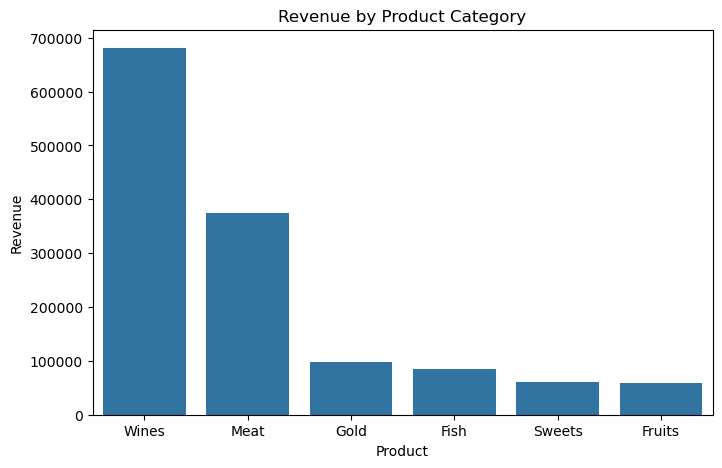

  Product  Revenue
0   Wines   680816
2    Meat   373968
5    Gold    98609
3    Fish    84057
4  Sweets    60621
1  Fruits    58917
Top-performing product = Highest revenue category
Lowest-performing product = Lowest revenue category
8b. Age vs Campaign Acceptance


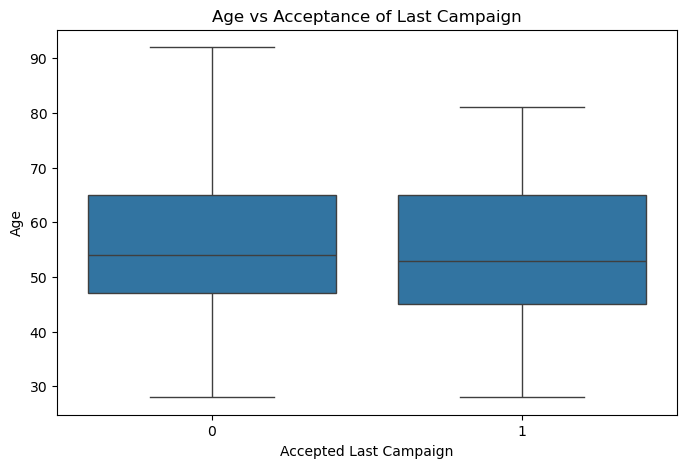

8c. Country with Highest Campaign Acceptance


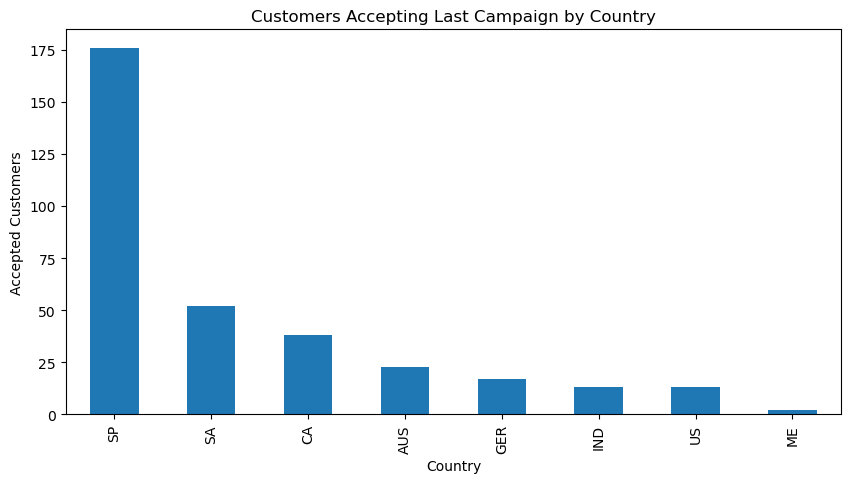

Country
SP     176
SA      52
CA      38
AUS     23
GER     17
IND     13
US      13
ME       2
Name: count, dtype: int64
The country appearing first has the highest number of customers who accepted the campaign.
8d. Children at Home vs Total Expenditure


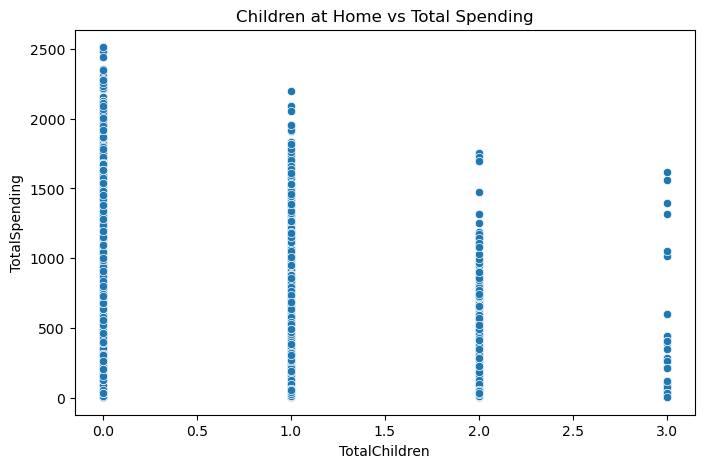

Higher spending for families with more children indicates larger household consumption.

Lower spending may indicate budget constraints associated with larger families.

8e. Education of Customers with Complaints


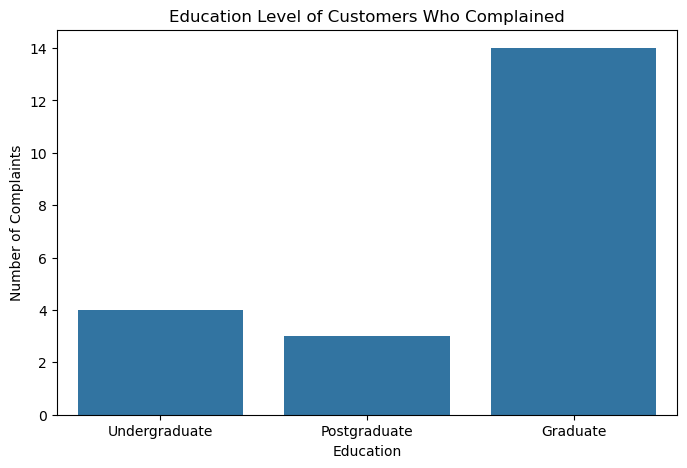

Education
Graduate         14
Undergraduate     4
Postgraduate      3
Name: count, dtype: int64
The education category with the highest count represents the group contributing the most complaints.


In [144]:
#8.	Use appropriate visualization to help analyze the following:
#   a.	Identify the top-performing products and those with the lowest revenue.
#   b.	Examine if there is a correlation between customers' age and the acceptance rate of the last campaign.
#   c.	Determine the country with the highest number of customers who accepted the last campaign.
#   d.	Investigate if there is a discernible pattern in the number of children at home and the total expenditure.
#   e.	Analyze the educational background of customers who lodged complaints in the last two years.

print("8a. Product Revenue Analysis")
# Product Revenue Analysis
product_sales = {
    "Wines": data["MntWines"].sum(),
    "Fruits": data["MntFruits"].sum(),
    "Meat": data["MntMeatProducts"].sum(),
    "Fish": data["MntFishProducts"].sum(),
    "Sweets": data["MntSweetProducts"].sum(),
    "Gold": data["MntGoldProds"].sum()
}

product_df = pd.DataFrame(
    product_sales.items(),
    columns=["Product", "Revenue"]
)

product_df = product_df.sort_values(
    by="Revenue",
    ascending=False
)

plt.figure(figsize=(8,5))

sns.barplot(
    data=product_df,
    x="Product",
    y="Revenue"
)

plt.title("Revenue by Product Category")
plt.show()

print(product_df)

print("Top-performing product = Highest revenue category\nLowest-performing product = Lowest revenue category")
print("================================================================================")
print("8b. Age vs Campaign Acceptance")
plt.figure(figsize=(8,5))

sns.boxplot(
    data=data,
    x="Response",
    y="Age"
)

plt.title(
    "Age vs Acceptance of Last Campaign"
)

plt.xlabel("Accepted Last Campaign")
plt.ylabel("Age")

plt.show()
print("================================================================================")
print("8c. Country with Highest Campaign Acceptance")
accepted_customers = data[
    data["Response"] == 1
]

country_acceptance = (
    accepted_customers["Country"]
    .value_counts()
)

plt.figure(figsize=(10,5))

country_acceptance.plot(
    kind="bar"
)

plt.title(
    "Customers Accepting Last Campaign by Country"
)

plt.xlabel("Country")
plt.ylabel("Accepted Customers")

plt.show()

print(country_acceptance)
print("The country appearing first has the highest number of customers who accepted the campaign.")
print("================================================================================")

print("8d. Children at Home vs Total Expenditure")
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=data,
    x="TotalChildren",
    y="TotalSpending"
)
plt.title(
    "Children at Home vs Total Spending"
)
plt.show()
print("Higher spending for families with more children indicates larger household consumption.\n")
print("Lower spending may indicate budget constraints associated with larger families.\n")
print("================================================================================")
print("8e. Education of Customers with Complaints")
complaints = data[
    data["Complain"] == 1
]

plt.figure(figsize=(8,5))

sns.countplot(
    data=complaints,
    x="Education"
)

plt.title(
    "Education Level of Customers Who Complained"
)

plt.xlabel("Education")
plt.ylabel("Number of Complaints")

plt.show()

print(
    complaints["Education"].value_counts()
)
print("The education category with the highest count represents the group contributing the most complaints.")